# VirtualShip Postprocessing

This notebook postprocesses the output of a [VirtualShip](https://virtualship.parcels-code.org/) virtual research cruise and makes quick-look plots of each instrument.

**Workflow:** `virtualship init` → edit `expedition.yaml` → `virtualship run` → run this notebook. See `virtualship_quickstart.md` for the first three steps.

**Inputs:** the Zarr output in `./results/` (created by `virtualship run`):

| File | Instrument | Section |
|---|---|---|
| `ctd.zarr` | CTD profiles | CTD |
| `adcp.zarr` | Ship-mounted ADCP | ADCP |
| `drifter.zarr` | Surface drifters | Drifter |
| `underwater_st.zarr` | Underway temperature/salinity (TSG) | TSG |

**Outputs:** vertical sections of temperature, salinity and velocity, maps of the cruise track, drifter trajectories and surface salinity, and cleaned NetCDF files.

**Requirements:** the `virtualship` conda environment plus `trajan` and `cartopy`. Run the notebook from the directory containing `results/`. Cells must be run in order, since later sections reuse variables (e.g. `plot_map`, `ctd_mod`) from earlier ones.

**Note:** the drifter and TSG cells write NetCDF files (`student_drifter.nc`, `student_tsg.nc`) to the working directory; change `name` in the setup cell to rename them.

## Setup

Import the libraries and set `path` to the VirtualShip results folder and `name` to the prefix used for saved files.

In [1]:
import numpy as np
import xarray as xr
import matplotlib.pyplot as plt
import trajan
from datetime import timedelta
import cartopy.crs as ccrs
import cartopy.feature as cfeature

In [2]:
# path to data
name='student'
path = f'./results/'

# CTD

Conductivity-Temperature-Depth profiles (temperature and salinity vs. depth) at each station.

This section loads `ctd.zarr`, defines a map helper (`plot_map`, reused in later sections) and plots the station locations.

In [3]:
# load data
ctd = xr.open_dataset(path+'ctd.zarr').load()

FileNotFoundError: No such file or directory: '/home/sryan/python/teaching/virtualship_example/results/ctd.zarr'

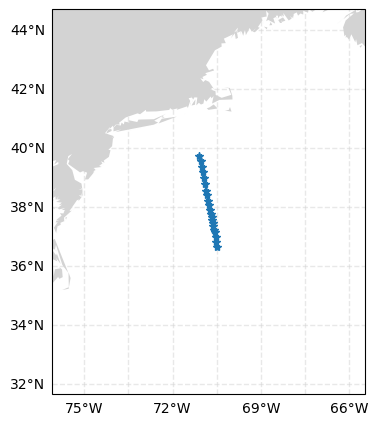

In [ ]:
def plot_map(ctd):

    latmin = ctd.lat.min()-5
    latmax = ctd.lat.max()+5
    lonmin = ctd.lon.min()-5
    lonmax = ctd.lon.max()+5
    
    # Create new figure & PlateCarree axis if needed
    fig, ax = plt.subplots(
        figsize=(6, 5),
        subplot_kw=dict(projection=ccrs.PlateCarree())
    )
    
    ax.set_extent([lonmin, lonmax, latmin, latmax])
     
    # Add gridlines
    gl = ax.gridlines(
        crs=ccrs.PlateCarree(), draw_labels=True,
        linewidth=1, color='lightgray', alpha=0.5, linestyle='--'
    )
    gl.top_labels = False
    gl.right_labels = False
    
    # Add GSHHS coastline
    ax.add_feature(
        cfeature.GSHHSFeature(scale='low'),
        facecolor='lightgray', edgecolor='None'
    )

    return fig,ax

# plot map
fig,ax = plot_map(ctd)
ax.plot(ctd.lon[:,0],ctd.lat[:,0],marker='*')

## Postprocessing

Code from https://virtualship.readthedocs.io/en/latest/user-guide/tutorials/CTD_transects.html

The next cell defines helper functions (great-circle distance, downcast extraction, etc.) and builds a clean dataset `ctd_mod` with dimensions `(station, depth)`.

- [x] separate into up and downcast and only use downcast
- [x] rename dimensions into something meaningful and set coordinates
- [x] add distance variable

In [ ]:
# utility functions


def haversine(lon1, lat1, lon2, lat2):
    """Great-circle distance (meters) between two points."""
    lon1, lat1, lon2, lat2 = map(np.radians, [lon1, lat1, lon2, lat2])
    dlon, dlat = lon2 - lon1, lat2 - lat1
    a = np.sin(dlat / 2) ** 2 + np.cos(lat1) * np.cos(lat2) * np.sin(dlon / 2) ** 2
    c = 2 * np.arctan2(np.sqrt(a), np.sqrt(1 - a))
    return 6371000 * c


def distance_from_start(ds):
    """Add 'distance' variable: meters from first waypoint."""
    lon0, lat0 = (
        ds.isel(trajectory=0)["lon"].values[0],
        ds.isel(trajectory=0)["lat"].values[0],
    )
    d = np.zeros_like(ds["lon"].values, dtype=float)
    for ob, (lon, lat) in enumerate(zip(ds["lon"], ds["lat"], strict=False)):
        d[ob] = haversine(lon, lat, lon0, lat0)
    ds["distance"] = xr.DataArray(
        d,
        dims=ds["lon"].dims,
        attrs={"long_name": "distance from first waypoint", "units": "m"},
    )
    return ds
    

def cum_distance(ds):
    " Cumulative distance along track in meters"
    d = np.zeros_like(ds["lon"][:,0].values, dtype=float)
    for i in range(len(ds['lon'][:,0])-1):
        d[i+1] = haversine(ds['lon'][i+1,0], ds['lat'][i+1,0], 
                           ds['lon'][i,0], ds['lat'][i,0]).values
    return np.cumsum(d)


def descent_only(ds, variable):
    """Extract descending CTD data (downcast), pad with NaNs for alignment."""
    min_z_idx = ds["z"].argmin("obs")
    da_clean = []
    for i, traj in enumerate(ds["trajectory"].values):
        idx = min_z_idx.sel(trajectory=traj).item()
        descent_vals = ds[variable][
            i, : idx + 1
        ]  # take values from surface to min_z_idx (inclusive)
        da_clean.append(descent_vals)
    max_len = max(len(arr[~np.isnan(arr)]) for arr in da_clean)
    da_padded = np.full((ds["trajectory"].size, max_len), np.nan)
    for i, arr in enumerate(da_clean):
        da_dropna = arr[~np.isnan(arr)]
        da_padded[i, : len(da_dropna)] = da_dropna
    return xr.DataArray(
        da_padded,
        dims=["trajectory", "obs"],
        coords={"trajectory": ds["trajectory"], "obs": np.arange(max_len)},
    )


def build_masked_array(data_up, profile_indices, n_profiles):
    arr = np.full((n_profiles, data_up.shape[1]), np.nan)
    for i, idx in enumerate(profile_indices):
        if idx is not None:
            arr[i, :] = data_up.values[idx, :]
    return arr


def get_profile_indices(distance_1d):
    """
    Returns regular distance bins and profile indices for CTD transect plotting.

    Bin size is set to one order of magnitude lower than max distance.
    """
    dist_min, dist_max = float(distance_1d.min()), float(distance_1d.max())
    if dist_max > 1e6:
        dist_step = 1e5
    elif dist_max > 1e5:
        dist_step = 1e4
    elif dist_max > 1e4:
        dist_step = 1e3
    else:
        dist_step = 1e2  # fallback for very short transects

    distance_regular = np.arange(dist_min, dist_max + dist_step, dist_step)
    threshold = dist_step / 2
    profile_indices = [
        np.argmin(np.abs(distance_1d.values - d))
        if np.min(np.abs(distance_1d.values - d)) < threshold
        else None
        for d in distance_regular
    ]
    return profile_indices, distance_regular

# add distance from start
ctd_distance = distance_from_start(ctd)

# exract descent-only data
z_down = descent_only(ctd, "z")
d_down = descent_only(ctd, "distance")
T_down = descent_only(ctd, 'temperature')
S_down = descent_only(ctd, 'salinity')

# 1d array of depth dimension (from deepest trajectory)
traj_idx, obs_idx = np.where(z_down == np.nanmin(z_down))
z1d = z_down.values[traj_idx[0], :]

# distance as 1d array
# distance_1d = d_down.isel(obs=0)
distance_1d = cum_distance(ctd)

# create a new xarray dataset
# number of stations
numsta = len(ctd.trajectory.values)

ctd_mod = xr.Dataset(
    data_vars={
        "temperature": (("station", "depth"), T_down.values),
        "salinity": (("station", "depth"), S_down.values),
        "distance": (("station"), distance_1d),
        "latitude": (("station"), ctd.lat[:,0].values),
        "longitude": (("station"), ctd.lon[:,0].values),
    },
    coords={
        "station": np.arange(numsta) + 1,
        "depth": z1d,
        "time": ctd.time[:,0].values,
    },
)

# save to netcdf
# ctd_mod.to_netcdf(f'./{name}_ctd.nc')

In [ ]:
ctd_mod

<xarray.Dataset> Size: 69kB
Dimensions:      (station: 21, depth: 200, time: 21)
Coordinates:
  * station      (station) int64 168B 1 2 3 4 5 6 7 8 ... 15 16 17 18 19 20 21
  * depth        (depth) float64 2kB -11.0 -20.0 -30.0 ... -1.99e+03 -2e+03
  * time         (time) datetime64[ns] 168B 2021-01-10T19:46:07 ... 2021-01-2...
Data variables:
    temperature  (station, depth) float64 34kB 20.31 20.31 20.31 ... nan nan nan
    salinity     (station, depth) float64 34kB 36.71 36.71 36.71 ... nan nan nan
    distance     (station) float64 168B 0.0 1.711e+04 ... 3.258e+05 3.443e+05
    latitude     (station) float32 84B 36.66 36.81 36.98 ... 39.38 39.56 39.72
    longitude    (station) float32 84B -70.49 -70.51 -70.54 ... -71.05 -71.09

### CTD sections

Temperature and salinity as a function of station and depth. Uncomment the `to_netcdf` line in the postprocessing cell to save `ctd_mod`.

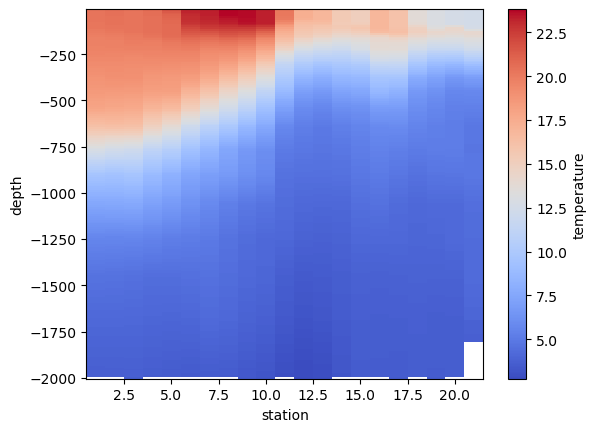

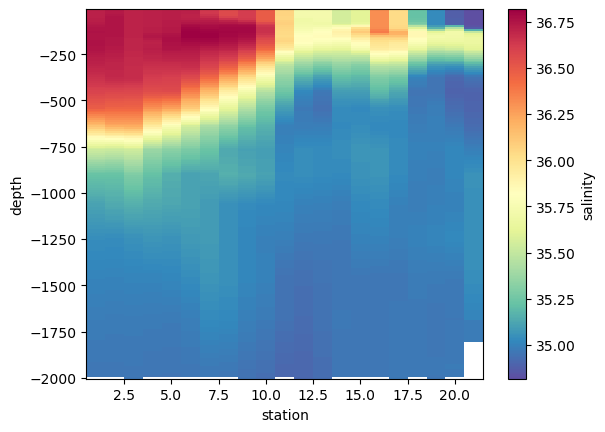

In [ ]:
# plot section

fig, ax = plt.subplots()
ctd_mod['temperature'].T.plot(ax=ax,cmap='coolwarm')

fig, ax = plt.subplots()
ctd_mod['salinity'].T.plot(ax=ax,cmap='Spectral_r')

# ADCP

Acoustic Doppler Current Profiler: ocean velocity (U, V) in depth bins along the ship track.

- [x] rename dimenions
- [x] derive distance as variable for plotting
- [x] rotate velocitites 
- [x] extract ADCP profile at CTD stations

In [ ]:
adcp = xr.open_zarr(path+'adcp.zarr/').load()
adcp['time'] = adcp.time.isel(trajectory=0)

## Postprocessing

Code from https://virtualship.readthedocs.io/en/latest/user-guide/tutorials/ADCP_transects.html 

The next cell computes speed, along-track (`Uparallel`) and cross-track (`Uperp`) velocity, and a mask for zero-velocity (land/sea bed) bins, then renames dimensions (`trajectory` → `bins`, `obs` → `time`).

- [x] calculates distance from start of section
- [x] rotates velocities to parallel and perpendicular components

**Sign convention:** the track angle is computed with `arctan2(dlat, dlon*cos(lat))`, so it follows the ship's actual heading. `Uparallel` is positive in the direction of travel (along-track) and `Uperp` is positive 90° to the left of travel. The signs are therefore relative to the cruise direction: the same physical flow (e.g. a northward current) is `Uparallel > 0` on a northbound leg but `Uparallel < 0` on a southbound leg, and the same flips for `Uperp`. Keep this in mind when comparing legs or cruises run in opposite directions, and use `U` and `V` (east/north) for a direction-independent view.

In [ ]:
# utility functions
def haversine(lon1, lat1, lon2, lat2):
    """Great-circle distance (meters) between two points."""
    lon1, lat1, lon2, lat2 = map(np.radians, [lon1, lat1, lon2, lat2])
    dlon, dlat = lon2 - lon1, lat2 - lat1
    a = np.sin(dlat / 2) ** 2 + np.cos(lat1) * np.cos(lat2) * np.sin(dlon / 2) ** 2
    c = 2 * np.arctan2(np.sqrt(a), np.sqrt(1 - a))
    return 6371000 * c
#
#
def distance_from_start(ds):
    """Array of meters from first waypoint."""
    lon0, lat0 = ds.isel(obs=0)["lon"].values, ds.isel(obs=0)["lat"].values
    d = np.zeros_like(ds["lon"].values, dtype=float)
    for ob, (lon, lat) in enumerate(zip(ds["lon"], ds["lat"], strict=False)):
        d[ob] = haversine(lon, lat, lon0, lat0)
    return d
#
#
def cum_distance(ds):
    " Cumulative distance along track in meters"
    d = np.zeros_like(ds["lon"].values, dtype=float)
    for i in range(len(ds['lon'])-1):
        d[i+1] = haversine(ds['lon'][i+1], ds['lat'][i+1], 
                           ds['lon'][i], ds['lat'][i]).values
    return np.cumsum(d)
#
#
def calc_velocities(ds):
    """Calculate absolute, parallel and perpendicular (to the ship trajectory) velocities, as well as (compass) direction of flow."""
    Uabs = np.sqrt(ds["U"] ** 2 + ds["V"] ** 2)
    ds_surface = ds.isel(trajectory=0)
    dlon = np.deg2rad(ds_surface["lon"].differentiate("obs"))
    dlat = np.deg2rad(ds_surface["lat"].differentiate("obs"))
    lat = np.deg2rad(ds_surface["lat"])
    alpha = np.arctan2(dlat, dlon * np.cos(lat))  # cruise heading angle (counter-clockwise from east)
    Uparallel = np.cos(alpha) * ds["U"] + np.sin(alpha) * ds["V"]
    Uperp = -np.sin(alpha) * ds["U"] + np.cos(alpha) * ds["V"]
    direction_rad = np.arctan2(
        ds["U"], ds["V"]
    )  # direction of flow [degrees from north]
    direction_deg = (np.degrees(direction_rad) + 360) % 360

    return Uabs, Uparallel, Uperp, direction_deg
#
#
#
# distance from start as 1d array
# distance_1d = distance_from_start(adcp.isel(trajectory=0))
distance_1d = cum_distance(adcp.isel(trajectory=0))

# calculate velocity components and direction
Uabs, Uparallel, Uperp, direction = calc_velocities(adcp)

# land / sea bed mask
landmask = xr.where(((adcp["U"] == 0) & (adcp["V"] == 0)), 1, np.nan)

# add derived variables to dataset
adcp["speed"] = Uabs
adcp["Uparallel"] = Uparallel
adcp["Uperp"] = Uperp
adcp["mask"] = landmask
adcp['distance'] = (('obs'),distance_1d)

# modify dataset a little before saving
adcp = adcp.rename({'trajectory':'bins'})
adcp = adcp.assign_coords(time=adcp.time)
adcp = adcp.swap_dims({"obs": "time"})

# --------------------------------------------------------------------------------
# pick ADCP at CTD stations
adcp_ctd_sta = adcp.sel(time=ctd_mod.time,method='nearest')

# --------------------------------------------------------------------------------
# save to netcdf
# adcp.to_netcdf(f'{name}_adcp.nc')
# adcp_ctd_sta.to_netcdf(f'{name}_adcp_ctd_stations.nc')

### ADCP track and velocity sections

Ship track map (star = start), then sections of along-track and cross-track velocity versus distance and depth. Colors are centered on zero.

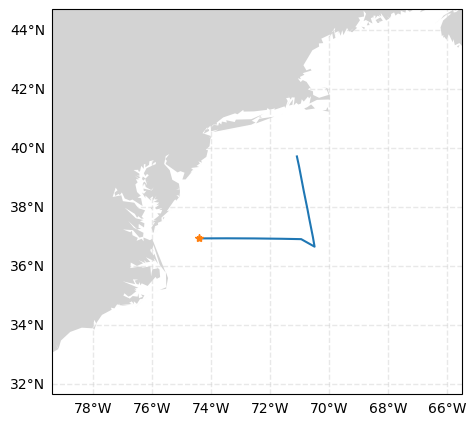

In [ ]:
fig,ax = plot_map(adcp)
plt.plot(adcp.lon[0,:],adcp.lat[0,:])
plt.plot(adcp.lon[0,0],adcp.lat[0,0],marker='*')

Text(0.5, 1.0, 'U parallel')

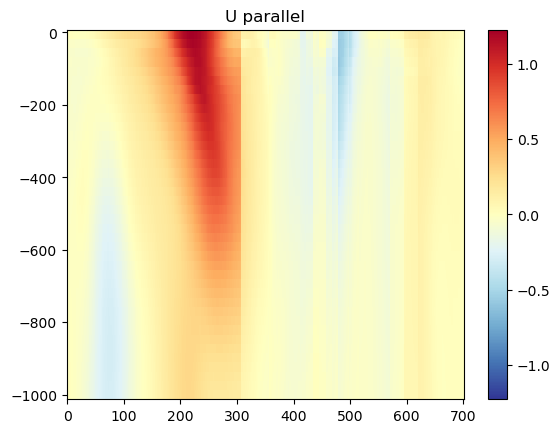

In [ ]:
import matplotlib.colors as mcolors
import matplotlib.patches as mpatches
plt.figure()
cc=plt.pcolormesh(
        adcp['distance']/1000,
        adcp["z"],
        adcp["Uparallel"].T,
        cmap='RdYlBu_r',norm=mcolors.CenteredNorm(vcenter=0))
plt.colorbar(cc,)
plt.title('U parallel')

Text(0.5, 1.0, 'U normal')

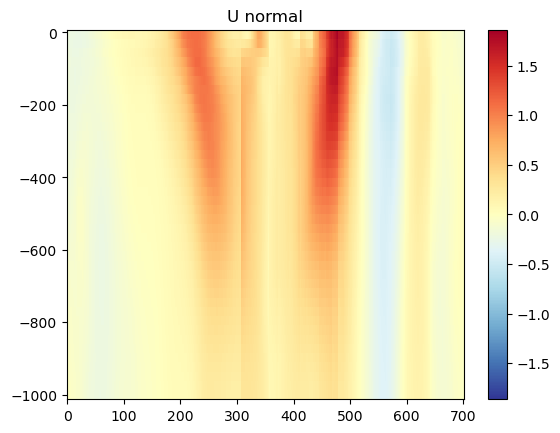

In [ ]:
import matplotlib.colors as mcolors
import matplotlib.patches as mpatches
plt.figure()
cc=plt.pcolormesh(
        adcp['distance']/1000,
        adcp["z"],
        adcp["Uperp"].T,
        cmap='RdYlBu_r',norm=mcolors.CenteredNorm(vcenter=0))
plt.colorbar(cc,)
plt.title('U perpendicular')

# Drifter

Surface drifters deployed during the cruise.

This section loads `drifter.zarr`, renames `trajectory` to `drifter`, drops unneeded variables, saves a NetCDF file and plots trajectories (stars = deployment points) with the CTD stations in red. The plotting loop assumes 6 drifters; adjust `range(6)` to match your `expedition.yaml`.

In [ ]:
drifter = xr.open_dataset(path+'drifter.zarr/').load()
drifter = drifter.rename({"trajectory":"drifter"})
drifter = drifter.drop_vars(['age','has_lifetime','lifetime','z'])
drifter['drifter'] = np.arange(1,len(drifter.drifter)+1)

# save to netcdf
drifter.to_netcdf(f'{name}_drifter.nc')

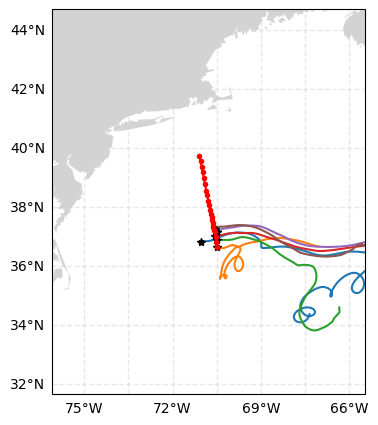

In [ ]:
fig,ax = plot_map(ctd)
for i in range(6):
    ax.plot(drifter['lon'][i,:],drifter['lat'][i,:])
    ax.plot(drifter['lon'][i,0],drifter['lat'][i,0],marker='*',color='k',linestyle='None')
# plt.plot(tsg.lon.squeeze(),tsg.lat.squeeze(),color='k')
ax.plot(ctd_mod.longitude,ctd_mod.latitude,marker='.',color='r',transform=ccrs.PlateCarree())
# ax.set_extent([-77,-58,32,45])

# TSG

Thermosalinograph: continuous underway sea-surface temperature and salinity measured along the ship track.

This section loads `underwater_st.zarr`, saves a NetCDF file and maps surface salinity along the track.

- [x] remove trajectory dimension

In [ ]:
tsg = xr.open_zarr(path+'underwater_st.zarr').load().squeeze()
tsg = tsg.squeeze()
tsg.to_netcdf(f'{name}_tsg.nc')

In [ ]:
tsg

<xarray.Dataset> Size: 23kB
Dimensions:      (obs: 712)
Coordinates:
  * obs          (obs) int32 3kB 0 1 2 3 4 5 6 7 ... 705 706 707 708 709 710 711
    trajectory   int64 8B 80
Data variables:
    lat          (obs) float32 3kB 36.94 36.94 36.94 36.94 ... 39.72 39.72 39.72
    lon          (obs) float32 3kB -74.39 -74.38 -74.36 ... -71.09 -71.09 -71.09
    salinity     (obs) float32 3kB 35.17 35.2 35.23 35.26 ... 34.82 34.82 34.82
    temperature  (obs) float32 3kB 14.48 14.57 14.66 14.74 ... 12.42 12.42 12.42
    time         (obs) datetime64[ns] 6kB 2021-01-02 ... 2021-01-28T12:36:10
    z            (obs) float32 3kB -2.0 -2.0 -2.0 -2.0 ... -2.0 -2.0 -2.0 -2.0
Attributes:
    Conventions:            CF-1.6/CF-1.7
    feature_type:           trajectory
    ncei_template_version:  NCEI_NetCDF_Trajectory_Template_v2.0
    parcels_kernels:        NewParticle_sample_temperature_sample_salinity
    parcels_mesh:           spherical
    parcels_version:        3.1.4

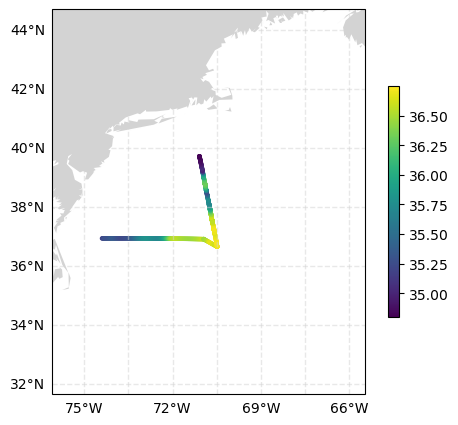

In [ ]:
fig,ax = plot_map(ctd)
cc=ax.scatter(tsg.lon.squeeze(),tsg.lat.squeeze(),c=tsg.salinity.squeeze(),s=5)
plt.colorbar(cc,shrink=0.6)